# 🌱 FarmerBud · 1. Training the 4 neural networks

This notebook trains the 4 networks used by the FarmerBud app (`2_FarmerBud_app_EN.ipynb`) and saves them in a single file, `modelli.joblib`.

| Network | What it predicts | What data it learns from |
|---|---|---|
| 1. **Yield** | relative yield (1.00 = normal year) | real ISTAT yields 2006-2025 + season climate + soil |
| 2. **Water** | irrigation water (mm) | results of the FAO-56 formula: the network must rebuild it from ET0, rain and crop |
| 3. **Nitrogen** | nitrogen to apply (kg N/ha) | results of the official fertilisation sheets: the network must rebuild them |
| 4. **Stability** | how much the yield changes from year to year (coefficient of variation, %) | real variability of ISTAT yields in each province |

For every network: data preparation, training one epoch at a time, **error plot** (to check that it is learning),
final exam on unseen data and comparison with a **naive** prediction. If the network does not beat the naive
prediction, it is useless: that is why the comparison is always there.

**Data:** the files in the `01_Datasets` folder (how they were built: `01_Datasets/README.md`).
On the team's computer they are read from there; on **Google Colab** the notebook downloads them by itself from the GitHub repository.

## 0. Libraries

In [1]:
# copy makes a full copy of a network (to keep the best version).
import copy

# os checks whether a file exists; urllib.request downloads a file from the internet.
import os
import urllib.request

# joblib saves the networks to a file, to use them in the app.
import joblib

# matplotlib.pyplot draws the plots; we call it "plt".
import matplotlib.pyplot as plt

# numpy does maths on lists of numbers; we call it "np".
import numpy as np

# pandas reads and handles tables (like Excel, but in Python); we call it "pd".
import pandas as pd

# sklearn is scikit-learn: we need its version number, saved together with the networks.
import sklearn

# mean_absolute_error computes the mean error: the average of |true - predicted|.
from sklearn.metrics import mean_absolute_error

# MLPRegressor is the scikit-learn neural network that predicts a number.
from sklearn.neural_network import MLPRegressor

# StandardScaler puts all columns on the same scale (mean 0, deviation 1).
from sklearn.preprocessing import StandardScaler

## 1. Read the data

In [2]:
# The project's GitHub repository: the notebook downloads the data from here when it cannot find them (e.g. on Colab).
REPO = "byterunnersAI/FarmerBud"


# Return the path of a project file; if it is not there, download it from GitHub.
def data_file(path):
    # On the team's computer the notebook is in 02_AI_Model, so the data are one folder up.
    if os.path.exists("../" + path):
        return "../" + path
    # Otherwise download the file (only once) into the current folder.
    name = path.split("/")[-1]
    if not os.path.exists(name):
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/{REPO}/main/{path}", name)
    return name


# Yields + season climate + soil: one row = province × crop × year.
yield_data = pd.read_csv(data_file("01_Datasets/dataset_modello.csv"))

# Irrigation water computed with FAO-56 for every province × crop × year.
water_data = pd.read_csv(data_file("01_Datasets/interim/acqua_anni.csv"))

# Nitrogen computed with the official sheets for every province × crop × year.
nitrogen_data = pd.read_csv(data_file("01_Datasets/interim/azoto_anni.csv"))

# Crop table: we need the median yield in t/ha of each crop.
crops = pd.read_csv(data_file("01_Datasets/colture.csv"))

# Name, region, coordinates and elevation of the lowland point of each province.
provinces = pd.read_csv(data_file("01_Datasets/interim/punti_province.csv"))

# Print how many rows each table has.
print("Yield:", len(yield_data), "· Water:", len(water_data), "· Nitrogen:", len(nitrogen_data))

Yield: 4967 · Water: 6600 · Nitrogen: 4967


## 2. Two functions we use for all 4 networks
Instead of writing the same code 4 times, we write it once inside a **function** and call it 4 times.

**`train_network`** creates a network and trains it one epoch at a time. One **epoch** = the network sees all
training rows once and updates its weights. After every epoch it measures the error on training and validation
data and keeps the network with the lowest validation error: after that point the network would start learning
by heart (*overfitting*).

**`plot_training`** draws the two error plots:
- on the left the **loss**, the error the network uses to correct its weights: if it goes down, the network is learning;
- on the right the **mean error** on training and validation data, in the network's unit of measure.

In [3]:
# Define the function: it receives the data, the shape of the network and how many epochs to run.
def train_network(X_train, y_train, X_val, y_val, hidden, alpha, epochs, unit, batch=64, verbose=True):
    # Create the network (still empty: the weights are random).
    net = MLPRegressor(
        hidden_layer_sizes=hidden,    # how many neurons in each hidden layer, e.g. (32, 16)
        activation="relu",            # activation: negative values become 0, the others stay the same
        learning_rate_init=0.001,     # how much the weights move at each correction: small = slow but stable
        alpha=alpha,                  # penalty on large weights: the higher it is, the less the network learns by heart
        batch_size=batch,             # the network corrects its weights every "batch" rows
        random_state=42,              # always the same initial weights: same result at every run
    )
    # Empty lists where we store the error after every epoch.
    err_train, err_val = [], []
    # The best network found so far: none at the start, with infinite error.
    best_err, best_epoch, best_net = float("inf"), 0, None
    # Repeat for every epoch, from 1 to "epochs".
    for epoch in range(1, epochs + 1):
        # One pass over all training data: the network predicts, measures the error and corrects its weights.
        net.partial_fit(X_train, y_train)
        # Mean error on training data, converted to the real unit (× unit).
        err_train.append(mean_absolute_error(y_train, net.predict(X_train)) * unit)
        # Mean error on validation data: data the network does not use to correct its weights.
        err_val.append(mean_absolute_error(y_val, net.predict(X_val)) * unit)
        # If it is the lowest validation error so far, save a copy of the network.
        if err_val[-1] < best_err:
            best_err, best_epoch, best_net = err_val[-1], epoch, copy.deepcopy(net)
    # Say which epoch was the best (if verbose is true).
    if verbose:
        print(f"Best: epoch {best_epoch}, validation error {best_err:.2f}")
    # Return the best network and the curves for the plot.
    return best_net, net.loss_curve_, err_train, err_val, best_epoch


# Define the function that draws the two error plots.
def plot_training(title, loss, err_train, err_val, best_epoch, unit_label):
    # Epoch numbers for the horizontal axis.
    epochs = range(1, len(loss) + 1)
    # One figure with two plots side by side: "left" and "right".
    fig, (left, right) = plt.subplots(1, 2, figsize=(13, 4))
    # Left: the loss of every epoch.
    left.plot(epochs, loss, color="tab:blue")
    left.set_title(f"{title}: loss during training")
    left.set_xlabel("Epoch")
    left.set_ylabel("Loss")
    # Right: mean error on training (blue) and validation (orange) data.
    right.plot(epochs, err_train, label="Train", color="tab:blue")
    right.plot(epochs, err_val, label="Validation", color="tab:orange")
    # Dashed line on the epoch of the best network.
    right.axvline(best_epoch, color="gray", linestyle="--", label=f"Best network ({best_epoch})")
    right.set_title(f"{title}: mean error")
    right.set_xlabel("Epoch")
    right.set_ylabel(unit_label)
    right.legend()
    # Fix the spacing and show the figure.
    plt.tight_layout()
    plt.show()


# Empty dictionary where we will put the 4 networks ready for the app.
models = {}

## 3. Network 1: yield
**Inputs:** the crop, 13 columns on the season climate, 6 on the soil, 3 on the location.
**Answer:** `resa_relativa` (relative yield: yield divided by the crop's normal yield, 1.00 = normal, 0.80 = 20% less).
**Split by year:** training 2006-2018, validation 2019-2021, test 2022-2025 (includes the 2022 drought).
We split by year because in real life the network must predict future years.

Best: epoch 138, validation error 12.78


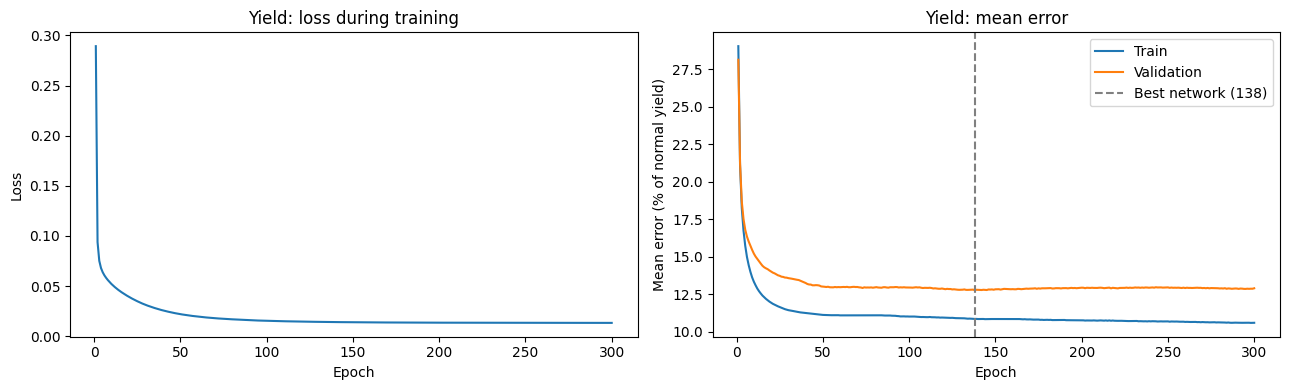

In [4]:
# Columns not given to the network: they are only used to split the data, or they are the answer.
not_inputs = ["cod_provincia", "anno", "periodo", "resa_relativa"]

# Remove those columns; get_dummies turns the crop (text) into one 0/1 column per crop.
X = pd.get_dummies(yield_data.drop(columns=not_inputs), columns=["cod_coltura"], dtype=float)

# The right answer.
y = yield_data["resa_relativa"]

# True/false for every row: which part it belongs to.
train = yield_data["anno"] <= 2018
val = yield_data["anno"].between(2019, 2021)
test = yield_data["anno"] >= 2022

# The scaler learns mean and deviation from training data only, so it does not peek at the other years.
scaler = StandardScaler().fit(X[train])

# Train the network: 2 layers of 32 and 16 neurons, alpha 0.1 (chosen by trying 0.001, 0.1 and 1 on validation data).
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.1, epochs=300, unit=100)

# Draw the error plots (× 100 = error in % of the normal yield).
plot_training("Yield", loss, err_train, err_val, best, "Mean error (% of normal yield)")

In [5]:
# The network predicts the relative yield for every test row.
prediction = net.predict(scaler.transform(X[test]))

# Naive prediction: every crop yields its 2006-2021 average.
naive = yield_data.loc[test, "cod_coltura"].map(yield_data[train | val].groupby("cod_coltura")["resa_relativa"].mean())

# Compare the two mean errors, in % of the normal yield.
print(f"Network error: {mean_absolute_error(y[test], prediction) * 100:.1f}%")
print(f"Naive prediction error: {mean_absolute_error(y[test], naive) * 100:.1f}%")

# 2022 table (drought): true, network and naive yield, average per crop.
year_2022 = yield_data.loc[test, ["anno", "cod_coltura"]].assign(true=y[test], network=prediction, naive=naive)
print(year_2022[year_2022["anno"] == 2022].groupby("cod_coltura")[["true", "network", "naive"]].mean().round(2))

# Save network, scaler and column order: the app needs all three.
models["yield"] = {"net": net, "scaler": scaler, "columns": list(X.columns)}

Network error: 14.4%
Naive prediction error: 15.0%
             true  network  naive
cod_coltura                      
BARLEY       1.10     1.03   1.00
BEETS        0.77     0.92   0.99
COMMEAT      1.02     1.06   1.01
MAIZE        0.81     0.89   0.99
RAPE         1.00     1.01   0.95
RICE         0.87     1.00   1.01
SORGH        0.87     0.92   0.98
SOYA         0.85     0.93   0.99
SUNFLO       0.96     0.89   0.98
WHEATD       1.01     1.07   0.97


### 3b. The hardest test: provinces never seen
In the app the farmer's field is almost always a **new place**. Let's simulate it: for each of the 33 provinces we
train a network **without** that province and ask it to predict only that one (*leave-one-province-out*).
It takes about one minute.

We measure two things:
1. **The mean error**, as before, against the naive prediction (the crop's average in the other provinces).
2. **The ranking**: this is the app's real job. For each province we take the 3 crops that actually did best and
   count how many the network gets right, how many the naive rule gets right and how many pure chance would.

We also look at the error **by region**, to see whether the network works worse in one area.

In [6]:
# Here we store, for every row, the network and naive predictions made "without seeing" its province.
left_out = yield_data[["cod_provincia", "cod_coltura", "anno", "resa_relativa"]].copy()
left_out["network"], left_out["naive"] = 0.0, 0.0

# All input columns of the yield network (the same as section 3).
X = pd.get_dummies(yield_data.drop(columns=not_inputs), columns=["cod_coltura"], dtype=float)
y = yield_data["resa_relativa"]

# Repeat for every province.
for province in yield_data["cod_provincia"].unique():
    # True for the rows of the province left out.
    out = yield_data["cod_provincia"] == province
    # Validation: the other provinces in 2019-2021 (only used to choose the epoch). Training: the other provinces in the other years.
    val = ~out & yield_data["anno"].between(2019, 2021)
    train = ~out & ~val
    scaler_lo = StandardScaler().fit(X[train])
    # Same network as section 3, with 150 epochs to be quicker and without printing anything.
    net_lo = train_network(scaler_lo.transform(X[train]), y[train], scaler_lo.transform(X[val]), y[val],
                           hidden=(32, 16), alpha=0.1, epochs=150, unit=100, verbose=False)[0]
    # Network prediction for the never-seen province.
    left_out.loc[out, "network"] = net_lo.predict(scaler_lo.transform(X[out]))
    # Naive prediction: the crop's average in the other provinces.
    left_out.loc[out, "naive"] = left_out.loc[out, "cod_coltura"].map(yield_data[~out].groupby("cod_coltura")["resa_relativa"].mean())

# 1. Mean error of network and naive rule, in % of normal yield.
print(f"Network error: {mean_absolute_error(left_out['resa_relativa'], left_out['network']) * 100:.1f}%")
print(f"Naive prediction error: {mean_absolute_error(left_out['resa_relativa'], left_out['naive']) * 100:.1f}%")

Network error: 15.3%
Naive prediction error: 15.1%


In [7]:
# 2. Ranking. Average relative yield of every crop in every province: true, network, naive.
averages = left_out.groupby(["cod_provincia", "cod_coltura"])[["resa_relativa", "network", "naive"]].mean()

# For every province with at least 5 crops: how many of the true top 3 the network, the naive rule and chance get right.
hits = []
for province, here in averages.groupby(level="cod_provincia"):
    if len(here) < 5:
        continue
    true_top3 = set(here["resa_relativa"].nlargest(3).index)
    hits.append({"network": len(true_top3 & set(here["network"].nlargest(3).index)) / 3,
                 "naive rule": len(true_top3 & set(here["naive"].nlargest(3).index)) / 3,
                 "chance": 3 / len(here)})

# Average over all provinces, in %.
print("Top crops guessed right (out of 3), on average, %")
print((pd.DataFrame(hits).mean() * 100).round(0))

Top crops guessed right (out of 3), on average, %
network       49.0
naive rule    41.0
chance        35.0
dtype: float64


In [8]:
# Mean error by region: does the network work equally well everywhere?
left_out = left_out.merge(provinces[["cod_provincia", "provincia", "regione"]], on="cod_provincia")
left_out["network_error"] = (left_out["network"] - left_out["resa_relativa"]).abs() * 100
left_out["naive_error"] = (left_out["naive"] - left_out["resa_relativa"]).abs() * 100
print(left_out.groupby("regione")[["network_error", "naive_error"]].mean().round(1))

# Where it fails most: the 5 rows with the biggest error.
print(left_out.nlargest(5, "network_error")[["provincia", "anno", "cod_coltura", "resa_relativa", "network", "naive"]].round(2))

                network_error  naive_error
regione                                   
Emilia-Romagna           14.7         14.5
Lombardia                15.4         15.1
Piemonte                 17.8         18.0
Veneto                   13.5         13.3
    provincia  anno cod_coltura  resa_relativa  network  naive
392    Biella  2012       MAIZE           1.60     0.78   0.99
210    Torino  2025        SOYA           1.51     0.74   1.00
432    Biella  2010        SOYA           1.43     0.67   1.00
343  Vercelli  2011      SUNFLO           0.32     1.06   0.99
342  Vercelli  2010      SUNFLO           0.32     1.05   0.99


## 4. Network 2: irrigation water
**Inputs:** cycle ET0 (how much water the air "asks for" from sowing to harvest), cycle rain, crop.
**Answer:** irrigation water in mm, computed with the FAO-56 formula. It is a **verification experiment**: the
network must rebuild a formula we know, starting from the raw ingredients.
The answer is divided by 100 (250 mm becomes 2.5): the network learns better with numbers close to 1.

Best: epoch 11, validation error 28.37


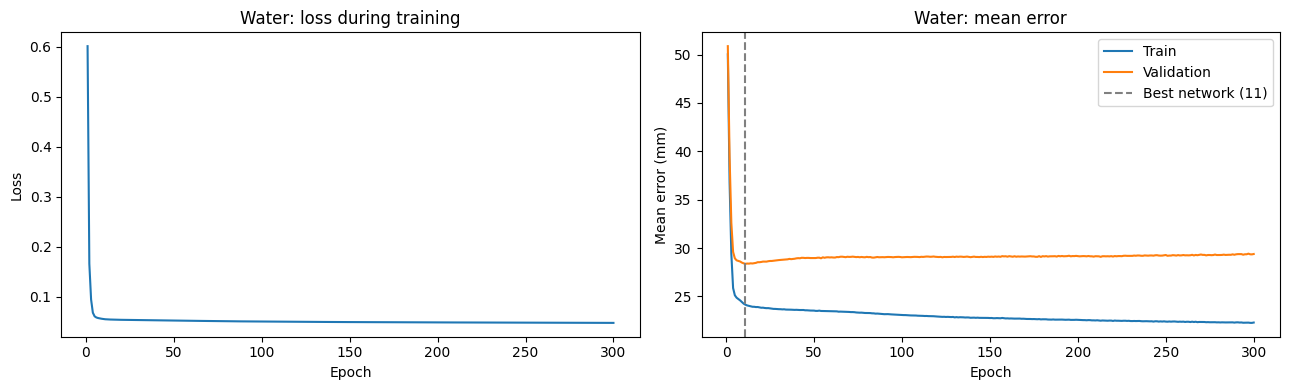

Network error: 30.9 mm
Naive prediction error: 73.4 mm


In [9]:
# Inputs: cycle ET0 and rain + the crop turned into 0/1 columns.
X = pd.get_dummies(water_data[["et0_ciclo_mm", "pioggia_ciclo_mm", "cod_coltura"]], columns=["cod_coltura"], dtype=float)

# The right answer in hundreds of mm.
y = water_data["irrigazione_mm"] / 100

# Same split by year as the yield network.
train = water_data["anno"] <= 2018
val = water_data["anno"].between(2019, 2021)
test = water_data["anno"] >= 2022

# Scaler fitted on training data only.
scaler = StandardScaler().fit(X[train])

# Small alpha: the data come from a formula, they have no "noise".
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.0001, epochs=300, unit=100)

# Error plots, in mm.
plot_training("Water", loss, err_train, err_val, best, "Mean error (mm)")

# Test prediction in mm; clip(min=0) because water cannot be negative.
prediction = (net.predict(scaler.transform(X[test])) * 100).clip(min=0)

# Naive prediction: the crop's average water in 2006-2021.
naive = water_data.loc[test, "cod_coltura"].map(water_data[train | val].groupby("cod_coltura")["irrigazione_mm"].mean())

# Compare the two mean errors, in mm.
print(f"Network error: {mean_absolute_error(y[test] * 100, prediction):.1f} mm")
print(f"Naive prediction error: {mean_absolute_error(y[test] * 100, naive):.1f} mm")

# Save the network for the app.
models["water"] = {"net": net, "scaler": scaler, "columns": list(X.columns)}

## 5. Network 3: nitrogen
**Inputs:** expected yield (t/ha), October-February rain, previous crop alfalfa (0/1), soil organic matter
(-1 low, 0 normal, 1 high), crop residues ploughed in (0/1), crop.
**Answer:** nitrogen in kg N/ha, computed with the official fertilisation sheets. This is also a verification experiment.
The farmer's choices do not exist in the ISTAT data: in the file they are simulated at random (see `s8_dataset_azoto.py`).

Best: epoch 500, validation error 5.87


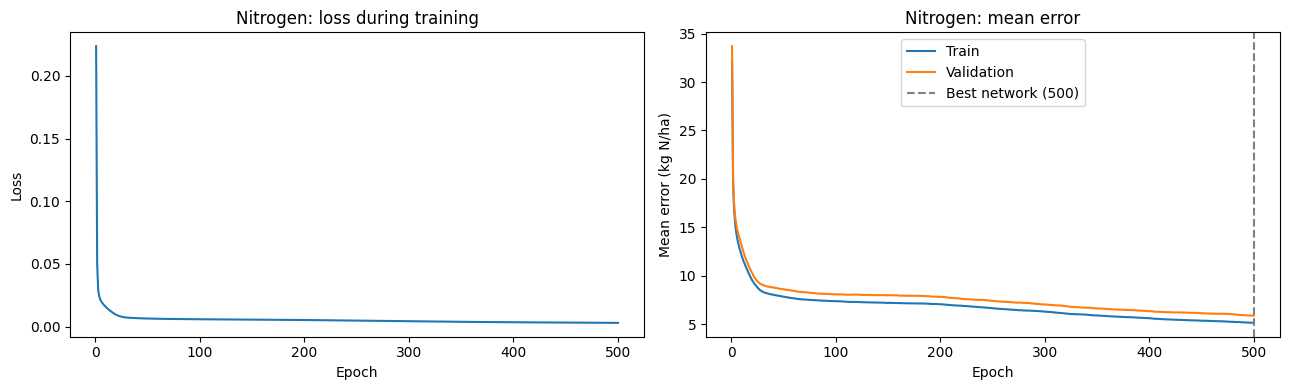

Network error: 6.2 kg/ha
Naive prediction error: 19.6 kg/ha


In [10]:
# The numeric input columns.
nitrogen_inputs = ["resa_t_ha", "pioggia_ott_feb_mm", "dopo_medica", "sostanza_organica", "residui_interrati"]

# Numeric inputs + crop turned into 0/1 columns.
X = pd.get_dummies(nitrogen_data[nitrogen_inputs + ["cod_coltura"]], columns=["cod_coltura"], dtype=float)

# The right answer in hundreds of kg/ha.
y = nitrogen_data["azoto_kg_ha"] / 100

# Same split by year.
train = nitrogen_data["anno"] <= 2018
val = nitrogen_data["anno"].between(2019, 2021)
test = nitrogen_data["anno"] >= 2022

# Scaler fitted on training data only.
scaler = StandardScaler().fit(X[train])

# 500 epochs: with 300 the error was still going down.
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(32, 16), alpha=0.0001, epochs=500, unit=100)

# Error plots, in kg/ha.
plot_training("Nitrogen", loss, err_train, err_val, best, "Mean error (kg N/ha)")

# Test prediction in kg/ha, never below zero.
prediction = (net.predict(scaler.transform(X[test])) * 100).clip(min=0)

# Naive prediction: the crop's average dose in 2006-2021.
naive = nitrogen_data.loc[test, "cod_coltura"].map(nitrogen_data[train | val].groupby("cod_coltura")["azoto_kg_ha"].mean())

# Compare the two mean errors, in kg/ha.
print(f"Network error: {mean_absolute_error(y[test] * 100, prediction):.1f} kg/ha")
print(f"Naive prediction error: {mean_absolute_error(y[test] * 100, naive):.1f} kg/ha")

# Save the network for the app.
models["nitrogen"] = {"net": net, "scaler": scaler, "columns": list(X.columns)}

## 6. Network 4: stability over the years
**What stable means.** For every province and crop we take the relative yield year by year and compute the
**coefficient of variation** (CV) = standard deviation ÷ mean × 100. CV 10% = the yield changes little; CV 25% = a lot.
We keep only the province × crop pairs with at least 10 years of data.

**Inputs:** the **average** season climate over the years, **how much** the climate changes from one year to the
next (standard deviation of rain, water balance, maximum temperatures, days above 35 °C, dry spell), soil, location, crop.

**Split by province.** Here there is only one row per province × crop, so we cannot split by year: we keep aside
6 provinces for validation and 7 for test, chosen at random with a fixed seed. It is the test closest to the app,
where the farmer's field is a new place.

**Warning:** there are only about 250 rows. That is why the network is tiny (8 neurons) and `alpha` is high (3):
with so little data a big network would learn by heart.

255 rows (province × crop)


Best: epoch 257, validation error 3.35


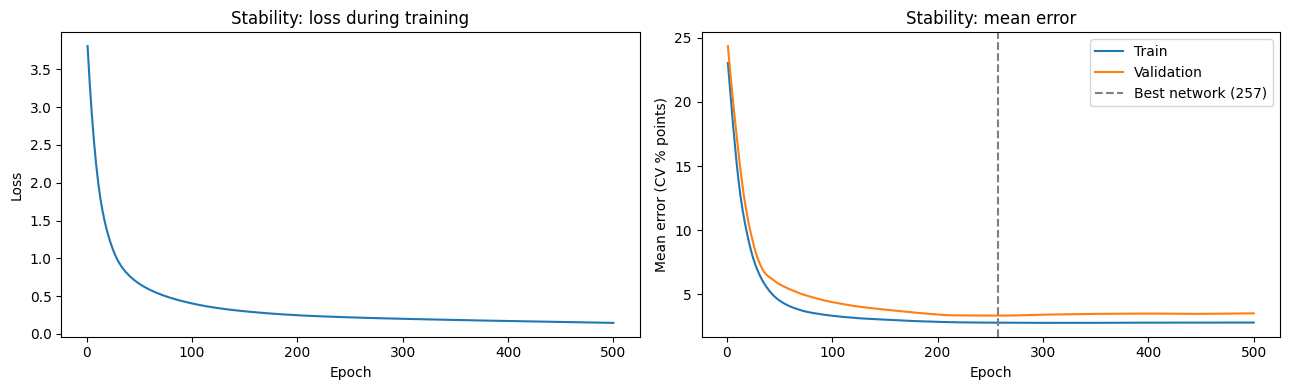

Network error: 3.8 CV points
Naive prediction error: 4.5 CV points


In [11]:
# The 13 season climate columns.
climate = ["temp_media", "temp_max_media", "temp_min_media", "pioggia_mm", "et0_mm", "bilancio_idrico_mm",
           "radiazione_MJ_m2", "umidita_media", "vento_medio_m_s", "gradi_giorno", "giorni_sopra_35",
           "giorni_gelo", "periodo_secco_max_giorni"]

# The columns for which we also measure how much they change from year to year.
climate_spread = ["bilancio_idrico_mm", "pioggia_mm", "temp_max_media", "giorni_sopra_35", "periodo_secco_max_giorni"]

# Soil and location: they are the same in all years of a province.
place = ["ph", "argilla_pct", "sabbia_pct", "limo_pct", "carbonio_organico_g_kg", "azoto_g_kg", "lat", "lon", "quota_m"]

# Group the rows by province and crop.
groups = yield_data.groupby(["cod_provincia", "cod_coltura"])

# One row per group: average climate, how much the climate changes (_std), soil and location, number of years.
stability_data = (groups[climate].mean()
                  .join(groups[climate_spread].std().add_suffix("_std"))
                  .join(groups[place].first())
                  .join(groups.size().rename("years")))

# The answer: the coefficient of variation of the relative yield, in %.
stability_data["cv_pct"] = groups["resa_relativa"].std() / groups["resa_relativa"].mean() * 100

# Keep only groups with at least 10 years and turn province and crop back into normal columns.
stability_data = stability_data[stability_data["years"] >= 10].reset_index()
print(len(stability_data), "rows (province × crop)")

# List of provinces shuffled at random, always in the same way (seed 0).
province_list = sorted(stability_data["cod_provincia"].unique())
np.random.default_rng(0).shuffle(province_list)

# The first 7 provinces go to the test, the next 6 to validation, the others to training.
test = stability_data["cod_provincia"].isin(province_list[:7])
val = stability_data["cod_provincia"].isin(province_list[7:13])
train = ~test & ~val

# Inputs: everything except province, years and answer; the crop becomes 0/1 columns.
X = pd.get_dummies(stability_data.drop(columns=["cod_provincia", "years", "cv_pct"]), columns=["cod_coltura"], dtype=float)

# The answer divided by 10 (CV 15% becomes 1.5).
y = stability_data["cv_pct"] / 10

# Scaler fitted on training data only.
scaler = StandardScaler().fit(X[train])

# Tiny network (8 neurons), high alpha (3), small batch because there are few rows.
net, loss, err_train, err_val, best = train_network(
    scaler.transform(X[train]), y[train], scaler.transform(X[val]), y[val],
    hidden=(8,), alpha=3, epochs=500, unit=10, batch=32)

# Error plots, in CV points.
plot_training("Stability", loss, err_train, err_val, best, "Mean error (CV % points)")

# Test prediction, in CV %.
prediction = net.predict(scaler.transform(X[test])) * 10

# Naive prediction: the crop's median CV in the training and validation provinces.
naive = stability_data.loc[test, "cod_coltura"].map(stability_data[train | val].groupby("cod_coltura")["cv_pct"].median())

# Compare the two mean errors.
print(f"Network error: {mean_absolute_error(y[test] * 10, prediction):.1f} CV points")
print(f"Naive prediction error: {mean_absolute_error(y[test] * 10, naive):.1f} CV points")

# Save the network for the app, with the lists of climate columns needed to build the inputs.
models["stability"] = {"net": net, "scaler": scaler, "columns": list(X.columns),
                       "climate": climate, "climate_spread": climate_spread}

## 7. Save everything in one file for the app
Together with the 4 networks we save:
- the **median yield in t/ha** of every crop, to turn the relative yield into t/ha;
- the **province table** (coordinates and soil), for the map and as backup soil if SoilGrids does not answer.

In [12]:
# Dictionary crop -> 2006-2021 median yield in t/ha.
models["crop_median_t_ha"] = dict(zip(crops["cod_coltura"], crops["resa_mediana_padana_2006_2021_t_ha"]))

# One row per province with soil and location, taken from the yield data (they are the same in all years).
soil = yield_data.groupby("cod_provincia")[place].first().reset_index()

# Add the name of the province and of the town used as the point.
models["provinces"] = soil.merge(provinces[["cod_provincia", "provincia", "comune_punto"]], on="cod_provincia")

# The scikit-learn version: the app warns if its own is different.
models["sklearn_version"] = sklearn.__version__

# Write everything to a single file.
joblib.dump(models, "modelli.joblib")
print("Saved modelli.joblib:", list(models))

Saved modelli.joblib: ['yield', 'water', 'nitrogen', 'stability', 'crop_median_t_ha', 'provinces', 'sklearn_version']
